# HW1 — Introduction and Learnability: PAC vs. Agnostic PAC
**Statistical and Machine Learning — M2, Université de Haute-Alsace**
**Author:** Jana Dannawi

## 0. Experimental setup
* Target threshold $\theta = 0.3$ (not centered, so the classes are unbalanced: 30% / 70%).
* Accuracy $\varepsilon = 0.05$ and confidence $\delta = 0.05$ (error at most 5%, with 95% confidence).
* Label noise $\eta = 0.2$ for the agnostic setting (clearly breaks realizability, but labels still carry information since $\eta < 0.5$).
* Training sizes $m \in \{5, 10, 20, 50, 100, 200\}$ (plus 500, 1000, 2000 in the agnostic case to see convergence).
* 1000 repetitions per size, and a test set of 100 000 points to estimate the true error.
* Hypothesis class: $\mathcal{H} = \{h_t(x) = \mathbb{1}[x > t] : t \in [0,1]\}$. Only `numpy` and `matplotlib` are used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


THETA   = 0.3
EPS     = 0.05
DELTA   = 0.05
ETA     = 0.2
M_LIST  = [5, 10, 20, 50, 100, 200]
N_REP   = 1000
N_TEST  = 100_000

rng = np.random.default_rng(seed=2026)   # fixed seed -> reproducible results
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Data Generation

In [2]:
def target(x,theta=THETA):
  return(x>theta).astype(int)
def generate_data(m,theta=THETA,eta=0.0,rng=rng):
  x=rng.uniform(0.0 ,1.0,size=m)
  y=target(x,theta)
  if eta>0:
    flip=rng.random(m)<eta
    y=np.where(flip,1-y,y)
  return x,y
#train test
datasets={m:generate_data(m)for m in M_LIST}
for m,(x,y)in datasets.items():
  print(f"m={m:3d}|class 0 :{np.sum(y==0):3d}|class 1:{np.sum(y==1):3d}")

m=  5|class 0 :  1|class 1:  4
m= 10|class 0 :  2|class 1:  8
m= 20|class 0 :  6|class 1: 14
m= 50|class 0 : 12|class 1: 38
m=100|class 0 : 28|class 1: 72
m=200|class 0 : 55|class 1:145


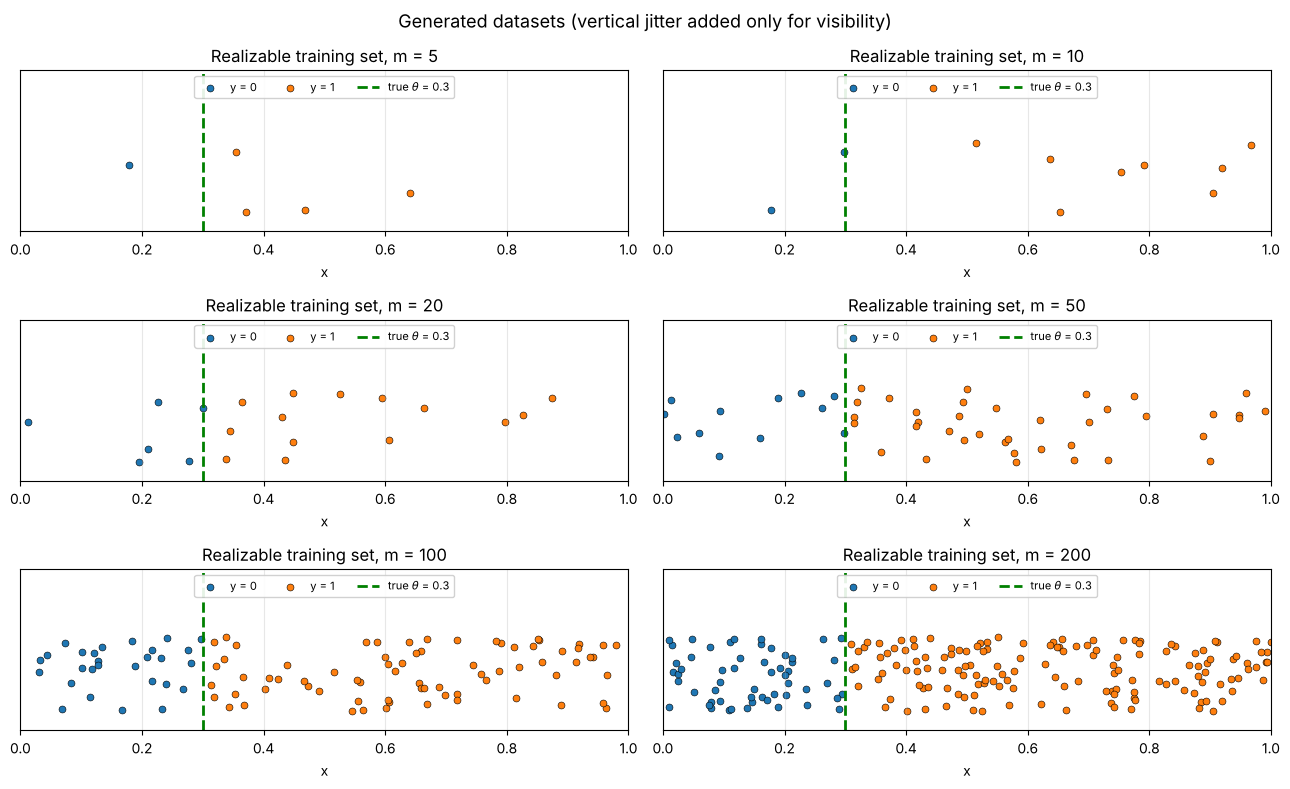

In [3]:
def plot_dataset(ax ,x,y,theta=THETA,title="" ,t_hat=None):
  jitter=np.random.default_rng(0).uniform(-0.3,0.3,size=len(x))
  ax.scatter(x[y == 0], jitter[y == 0], c="tab:blue", label="y = 0", s=25, edgecolor="k", lw=0.4)
  ax.scatter(x[y == 1], jitter[y == 1], c="tab:orange", label="y = 1", s=25, edgecolor="k", lw=0.4)
  ax.axvline(theta, color="green", ls="--", lw=2, label=fr"true $\theta$ = {theta}")
  if t_hat is not None:
      ax.axvline(t_hat, color="red", lw=2, label=fr"ERM $\hat t$ = {t_hat:.3f}")
  ax.set_xlim(0, 1); ax.set_ylim(-0.45, 0.85); ax.set_yticks([])
  ax.set_xlabel("x"); ax.set_title(title)
  ax.legend(loc="upper center", fontsize=8, ncol=4, framealpha=0.9)


fig, axes = plt.subplots(3, 2, figsize=(13, 8))
for ax, m in zip(axes.ravel(), M_LIST):
    plot_dataset(ax, *datasets[m], title=f"Realizable training set, m = {m}")
plt.suptitle("Generated datasets (vertical jitter added only for visibility)", fontsize=13)
plt.tight_layout()

**Interpretation.** In the realizable setting, the two classes are perfectly separated by the green line $x=\theta$: all blue points ($y=0$) are on the left and all orange points ($y=1$) are on the right. For small $m$, the gap between the last 0 and the first 1 is wide, so the position of $\theta$ is very uncertain. As $m$ grows, the points fill the interval and the gap around $\theta$ shrinks.

## 2. Implementation of ERM

ERM returns $\hat h = \arg\min_{h_t\in\mathcal{H}} L_S(h_t)$.

**Key observation.** Although $\mathcal{H}$ is infinite (one hypothesis per $t\in[0,1]$), on a sample of $m$ points only $m+1$ **different behaviours** are possible: sort the points $x_{(1)}<\dots<x_{(m)}$; any $t$ in the same gap $(x_{(k)},x_{(k+1)})$ predicts $0$ for the first $k$ points and $1$ for the others, hence has the same empirical error. So it is enough to test one threshold per gap.

**Strategy (complexity $O(m\log m)$):**
1. Sort the sample by $x$.
2. For $k=0,\dots,m$ (number of points predicted 0), the number of mistakes is
$$\text{err}(k)=\underbrace{\#\{i\le k : y_{(i)}=1\}}_{\text{1's predicted 0}}+\underbrace{\#\{i>k : y_{(i)}=0\}}_{\text{0's predicted 1}},$$
computed for all $k$ at once with cumulative sums.
3. Take $k^\star=\arg\min_k \text{err}(k)$ and return the **midpoint** of the corresponding gap, $\hat t=(x_{(k^\star)}+x_{(k^\star+1)})/2$ (with $x_{(0)}=0$, $x_{(m+1)}=1$).

Choosing the midpoint is a tie-breaking rule: every $t$ in the gap is an ERM solution; the midpoint is the "safest" one since it stays as far as possible from both neighbouring points.

In the realizable case $k^\star$ is exactly the number of 0's, so $\hat t$ lies between the largest negative point and the smallest positive one, and $L_S(\hat h)=0$.
(I used AI to help me write the equations and symbols clearly and correctly.)

In [4]:
def erm_threshold(x, y):
    order = np.argsort(x)
    xs, ys = x[order], y[order]
    m = len(xs)

    k = np.arange(m + 1)
    ones_before  = np.concatenate([[0], np.cumsum(ys)])
    zeros_after  = (m - k) - (ys.sum() - ones_before)
    errors = ones_before + zeros_after

    k_star = int(np.argmin(errors))
    bounds = np.concatenate([[0.0], xs, [1.0]])
    t_hat = 0.5 * (bounds[k_star] + bounds[k_star + 1])
    return t_hat, errors[k_star] / m


def empirical_error(t, x, y):

    return np.mean((x > t).astype(int) != y)



grid = np.linspace(0, 1, 20001)
for eta in [0.0, ETA]:
    worst = 0.0
    for _ in range(200):
        x, y = generate_data(30, eta=eta)
        t_hat, err = erm_threshold(x, y)
        brute = min(empirical_error(t, x, y) for t in grid[::20])
        worst = max(worst, err - brute)
        assert abs(err - empirical_error(t_hat, x, y)) < 1e-12
    print(f"eta = {eta}: max(ERM error - brute force error) over 200 samples = {worst:.4f}")

eta = 0.0: max(ERM error - brute force error) over 200 samples = 0.0000
eta = 0.2: max(ERM error - brute force error) over 200 samples = 0.0000


The difference is never positive: our ERM always finds a threshold at least as good as a brute-force search, so it really returns a minimiser of $L_S$. Let us visualise the learned threshold on two datasets.

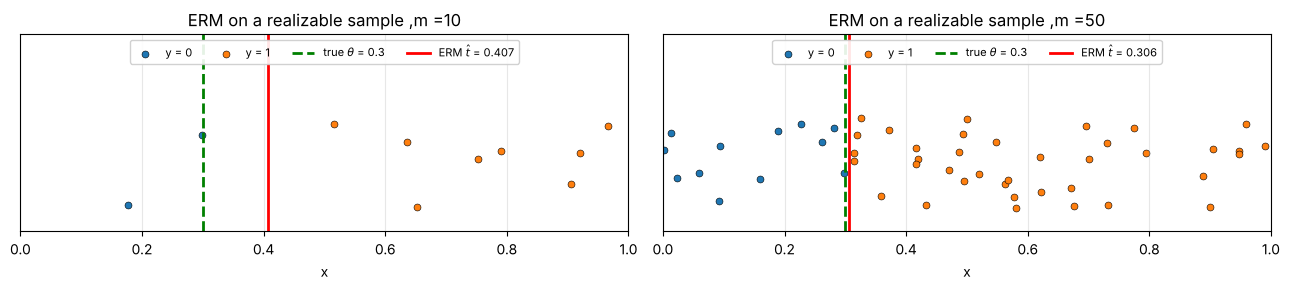

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,3))
for ax , m in zip(axes ,[10,50]):
  x,y=datasets[m]
  t_hat,_=erm_threshold(x,y)
  plot_dataset(ax,x,y,title=f'ERM on a realizable sample ,m ={m}',t_hat=t_hat)
plt.tight_layout()

## 3. Performance evaluation: empirical error vs. true error

For each training set, I compute the empirical error on the training data and the true error on a large independent test set (100 000 points), and I check it against the exact formula $L_\mathcal{D}(h_t) = \eta + (1-2\eta)|t-\theta|$.

In [6]:
def true_error_test(t,theta=THETA, eta=0.0 ,n_test=N_TEST ,rng=rng):
    x_test , y_test = generate_data(n_test , theta ,eta,rng)
    return np.mean((x_test>t).astype(int)!=y_test)
def true_error_exact(t, theta=THETA ,eta=0.0):
    return eta +(1- 2 * eta) *np.abs(t - theta)
print(f"{'m':>4} | {'t_hat':>7} | {'L_S (train)':>11} | {'L_D (test set)':>14} | {'L_D (exact)':>11}")
print("-" * 60)
for m in M_LIST:
    x, y = datasets[m]
    t_hat, emp = erm_threshold(x, y)
    print(f"{m:4d} | {t_hat:7.4f} | {emp:11.4f} | {true_error_test(t_hat):14.4f} | {true_error_exact(t_hat):11.4f}")



   m |   t_hat | L_S (train) | L_D (test set) | L_D (exact)
------------------------------------------------------------
   5 |  0.2669 |      0.0000 |         0.0322 |      0.0331
  10 |  0.4067 |      0.0000 |         0.1076 |      0.1067
  20 |  0.3194 |      0.0000 |         0.0193 |      0.0194
  50 |  0.3058 |      0.0000 |         0.0059 |      0.0058
 100 |  0.3050 |      0.0000 |         0.0051 |      0.0050
 200 |  0.3026 |      0.0000 |         0.0025 |      0.0026


**Interpretation.** In the realizable setting, the empirical error is 0 for every m: since there is no noise, ERM can always place the threshold between the last point labeled 0 and the first point labeled 1. However, the true error is not 0: it equals the distance between $\hat t$ and $\theta$. For m = 5, $\hat t = 0.2669$, so the true error is about 0.033, and for m = 200 it is only about 0.0026. The decrease is not perfectly regular: for m = 10 the error (0.107, with $\hat t = 0.4067$) is even larger than for m = 5, just by chance, because we used only one training set per size. This is why we repeat the experiment many times below. Finally, the test-set estimate is almost identical to the exact formula, which shows that 100 000 test points are enough to estimate the true error.

m =   5: mean L_S = 0.0000   mean L_D = 0.0713
m =  10: mean L_S = 0.0000   mean L_D = 0.0454
m =  20: mean L_S = 0.0000   mean L_D = 0.0221
m =  50: mean L_S = 0.0000   mean L_D = 0.0096
m = 100: mean L_S = 0.0000   mean L_D = 0.0044
m = 200: mean L_S = 0.0000   mean L_D = 0.0027


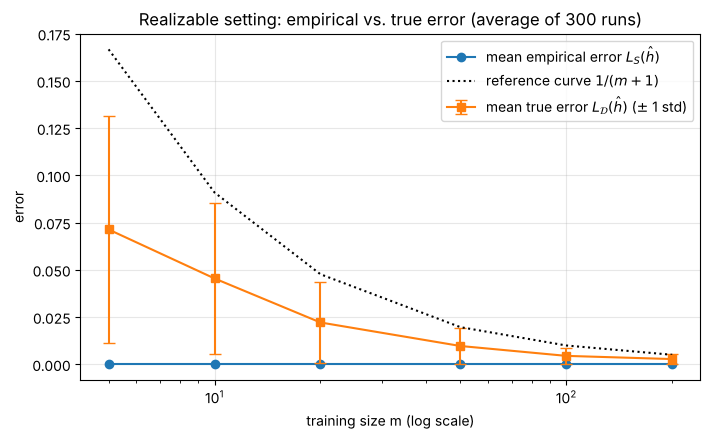

In [7]:
N_AVG=300
mean_emp , mean_true , std_true =[],[],[]
for m in M_LIST:
  emps , trues =[],[]
  for _ in range(N_AVG):
     x,y = generate_data(m)
     t_hat,emp=erm_threshold(x,y)
     emps.append(emp)
     trues.append(true_error_test(t_hat , n_test=20_000))
  mean_emp.append(np.mean(emps)); mean_true.append(np.mean(trues)); std_true.append(np.std(trues))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(M_LIST, mean_emp, "o-", label=r"mean empirical error $L_S(\hat h)$")
ax.errorbar(M_LIST, mean_true, yerr=std_true, fmt="s-", capsize=4, label=r"mean true error $L_\mathcal{D}(\hat h)$ ($\pm$ 1 std)")
ax.plot(M_LIST, [1 / (m + 1) for m in M_LIST], "k:", label=r"reference curve $1/(m+1)$")
ax.set_xscale("log"); ax.set_xlabel("training size m (log scale)"); ax.set_ylabel("error")
ax.set_title(f"Realizable setting: empirical vs. true error (average of {N_AVG} runs)")
ax.legend()
for m, e, t in zip(M_LIST, mean_emp, mean_true):
    print(f"m = {m:3d}: mean L_S = {e:.4f}   mean L_D = {t:.4f}")


**Interpretation .** The mean empirical error stays at **0** for every m, as expected in the realizable setting. The mean true error decreases steadily with m, roughly half of 1/(m+1) (e.g. 0.022 vs 0.048 at m = 20). This is consistent with the midpoint threshold, so the error decays in O(1/m). The standard deviation also shrinks: with few points the error varies a lot from one training set to another, while with large m it becomes small and stable. Averaging removes the noise seen in single runs and shows the expected 1/m behaviour.

## 4. Experimental verification of PAC learning

For each m, I repeat the experiment 1000 times with a new training set, and I estimate $\Pr(L_\mathcal{D}(\hat h) > \varepsilon)$ as the fraction of runs where the true error is larger than $\varepsilon$.

In [8]:
def run_experiment(m_list, eta=0.0, n_rep=N_REP, theta=THETA, rng=rng):
    # For each m: n_rep independent training sets -> ERM -> (empirical error, exact true error)
    emp = np.zeros((len(m_list), n_rep))
    true = np.zeros((len(m_list), n_rep))
    for i, m in enumerate(m_list):
        for r in range(n_rep):
            x, y = generate_data(m, theta, eta, rng)
            t_hat, emp[i, r] = erm_threshold(x, y)
            true[i, r] = true_error_exact(t_hat, theta, eta)
    return emp, true


emp_R, true_R = run_experiment(M_LIST, eta=0.0)
p_fail_R = np.mean(true_R > EPS, axis=1)
bound_R = np.minimum(1, 2 * (1 - EPS) ** np.array(M_LIST))
m_needed = int(np.ceil(np.log(2 / DELTA) / EPS))

print(f"epsilon = {EPS}, delta = {DELTA}  ->  theoretical sufficient size m >= log(2/delta)/eps = {m_needed}\n")
print(f"{'m':>4} | {'Pr(L > eps) estimated':>22} | {'bound 2(1-eps)^m':>16} | {'<= delta ?':>10}")
print("-" * 63)
for m, p, b in zip(M_LIST, p_fail_R, bound_R):
    print(f"{m:4d} | {p:22.3f} | {b:16.3f} | {str(p <= DELTA):>10}")

epsilon = 0.05, delta = 0.05  ->  theoretical sufficient size m >= log(2/delta)/eps = 74

   m |  Pr(L > eps) estimated | bound 2(1-eps)^m | <= delta ?
---------------------------------------------------------------
   5 |                  0.571 |            1.000 |      False
  10 |                  0.377 |            1.000 |      False
  20 |                  0.133 |            0.717 |      False
  50 |                  0.006 |            0.154 |       True
 100 |                  0.000 |            0.012 |       True
 200 |                  0.000 |            0.000 |       True


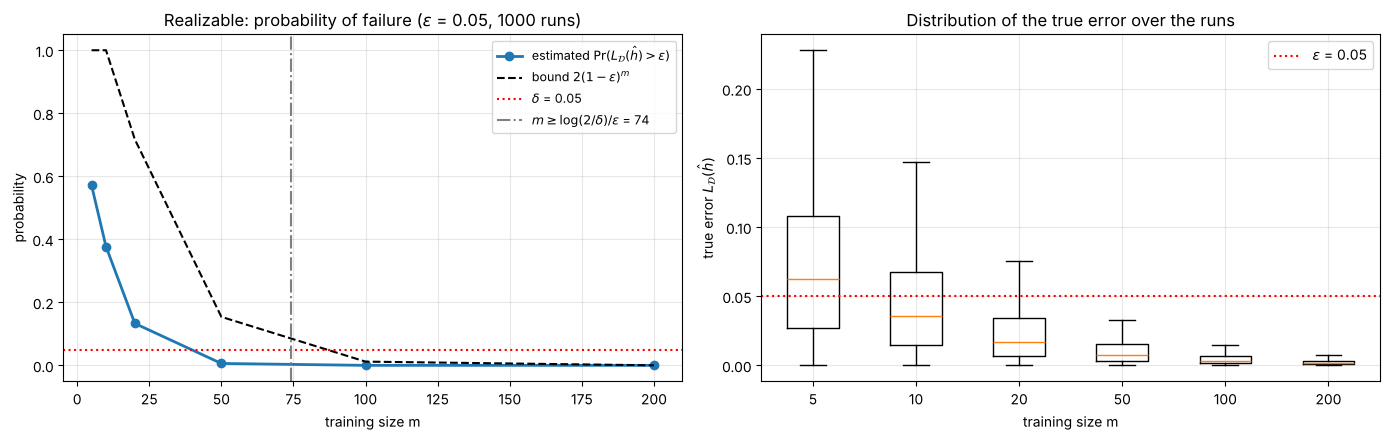

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.plot(M_LIST, p_fail_R, "o-", lw=2, label=r"estimated $\Pr(L_\mathcal{D}(\hat h)>\varepsilon)$")
ax.plot(M_LIST, bound_R, "k--", label=r"bound $2(1-\varepsilon)^m$")
ax.axhline(DELTA, color="red", ls=":", label=fr"$\delta$ = {DELTA}")
ax.axvline(m_needed, color="gray", ls="-.", label=fr"$m \geq \log(2/\delta)/\varepsilon$ = {m_needed}")
ax.set_xlabel("training size m"); ax.set_ylabel("probability")
ax.set_title(fr"Realizable: probability of failure ($\varepsilon$ = {EPS}, {N_REP} runs)")
ax.legend(fontsize=9)

ax = axes[1]
ax.boxplot(true_R.T, tick_labels=[str(m) for m in M_LIST], showfliers=False)
ax.axhline(EPS, color="red", ls=":", label=fr"$\varepsilon$ = {EPS}")
ax.set_xlabel("training size m"); ax.set_ylabel(r"true error $L_\mathcal{D}(\hat h)$")
ax.set_title("Distribution of the true error over the runs")
ax.legend()
plt.tight_layout()

**Interpretation.** The left plot shows that the probability of failure $\Pr(L_\mathcal{D}(\hat h) > \varepsilon)$ decreases very quickly when m increases: it is about 0.57 for m = 5, about 0.13 for m = 20, and almost 0 from m = 50. The experimental curve (blue) is always below the theoretical bound $2(1-\varepsilon)^m$ (dashed black), so the bound is verified; it is pessimistic because it is a worst-case guarantee. The theory says that m ≥ 74 examples are enough to get a failure probability below δ = 0.05, but in our experiment this already happens at m = 50 (and at m = 30 in the finer study below), so in practice fewer examples are needed. The right plot shows the distribution of the true error over the 1000 runs: the boxes become smaller and closer to 0 when m increases, so the true error becomes small and stable. This is exactly the PAC guarantee: with enough training data, ERM is probably (probability ≥ 1 − δ) approximately (error ≤ ε) correct.

eps = 0.01: theoretical m >=  369 | smallest tested m with Pr(L > eps) <= delta: 150
eps = 0.05: theoretical m >=   74 | smallest tested m with Pr(L > eps) <= delta: 30
eps = 0.10: theoretical m >=   37 | smallest tested m with Pr(L > eps) <= delta: 20


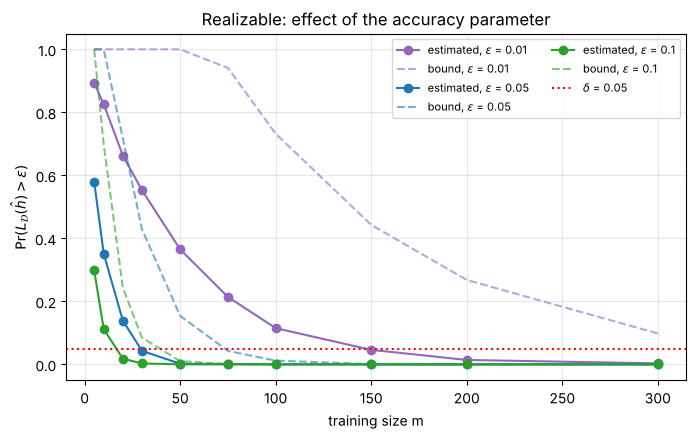

In [10]:
M_FINE = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300]
emp_fine, true_fine = run_experiment(M_FINE, eta=0.0, n_rep=N_REP)

fig, ax = plt.subplots(figsize=(8, 4.5))
for eps, c in zip([0.01, 0.05, 0.10], ["tab:purple", "tab:blue", "tab:green"]):
    ax.plot(M_FINE, np.mean(true_fine > eps, axis=1), "o-", color=c, label=fr"estimated, $\varepsilon$ = {eps}")
    ax.plot(M_FINE, np.minimum(1, 2 * (1 - eps) ** np.array(M_FINE)), "--", color=c, alpha=0.6,
            label=fr"bound, $\varepsilon$ = {eps}")
    print(f"eps = {eps:4.2f}: theoretical m >= {int(np.ceil(np.log(2 / DELTA) / eps)):4d} | "
          f"smallest tested m with Pr(L > eps) <= delta: "
          f"{next((m for m, p in zip(M_FINE, np.mean(true_fine > eps, axis=1)) if p <= DELTA), '> 300')}")
ax.axhline(DELTA, color="red", ls=":", label=fr"$\delta$ = {DELTA}")
ax.set_xlabel("training size m"); ax.set_ylabel(r"$\Pr(L_\mathcal{D}(\hat h)>\varepsilon)$")
ax.set_title("Realizable: effect of the accuracy parameter")
ax.legend(fontsize=8, ncol=2)

**Interpretation.** For every $\varepsilon$ the failure probability goes to 0, but the smaller $\varepsilon$, the more examples are needed. This matches the $1/\varepsilon$ dependence of the sample complexity $m_\mathcal{H}(\varepsilon,\delta)$.

## 5. From PAC to Agnostic PAC
Now each label is flipped with probability $\eta = 0.2$. The realizability assumption no longer holds: no threshold can have zero true error, and the best possible error in the class is $\eta = 0.2$ (obtained with the true threshold $\theta$).
So I estimate two probabilities:
* $\Pr(L_\mathcal{D}(\hat h) > \varepsilon)$: the PAC criterion, which can no longer be satisfied;
* $\Pr(L_\mathcal{D}(\hat h) > \eta + \varepsilon)$: the Agnostic PAC criterion, which compares $\hat h$ with the best hypothesis of the class.

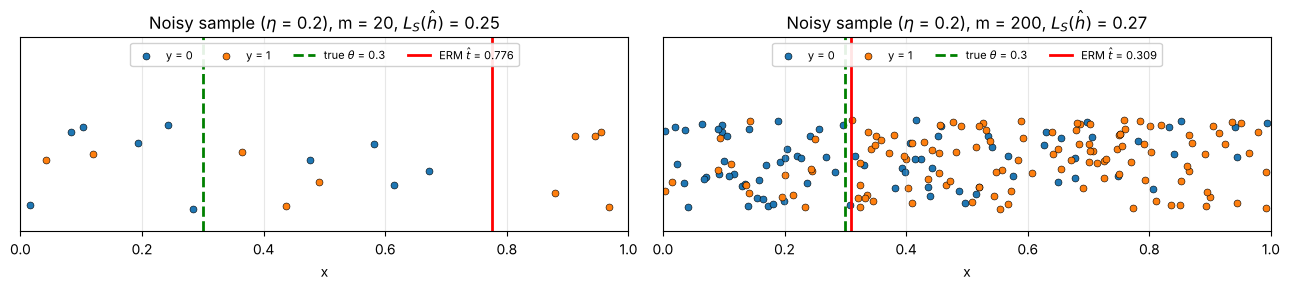

In [11]:
# one noisy dataset, visualised with the ERM threshold
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
for ax, m in zip(axes, [20, 200]):
    x, y = generate_data(m, eta=ETA)
    t_hat, emp = erm_threshold(x, y)
    plot_dataset(ax, x, y, title=fr"Noisy sample ($\eta$ = {ETA}), m = {m}, $L_S(\hat h)$ = {emp:.2f}", t_hat=t_hat)
plt.tight_layout()

With noise, some points labeled 1 appear on the left of θ and some points labeled 0 on the right: no threshold can separate the two classes, so ERM must accept some training errors.

In [12]:
M_AGN = M_LIST + [500, 1000, 2000]          # larger sizes added to observe convergence
emp_A, true_A = run_experiment(M_AGN, eta=ETA)
emp_R2, true_R2 = run_experiment(M_AGN, eta=0.0)

p_pac_A   = np.mean(true_A > EPS, axis=1)               # PAC criterion
p_apac_A  = np.mean(true_A > ETA + EPS, axis=1)         # agnostic PAC criterion
p_pac_R   = np.mean(true_R2 > EPS, axis=1)
zero_A    = np.mean(emp_A == 0, axis=1)

print(f"Noise eta = {ETA}  ->  best achievable error min_h L_D(h) = {ETA}\n")
print(f"{'m':>5} | {'mean L_S':>8} | {'mean L_D':>8} | {'Pr(L_S=0)':>9} | {'Pr(L_D>eps)':>11} | {'Pr(L_D>eta+eps)':>15}")
print("-" * 72)
for i, m in enumerate(M_AGN):
    print(f"{m:5d} | {emp_A[i].mean():8.3f} | {true_A[i].mean():8.3f} | {zero_A[i]:9.3f} | "
          f"{p_pac_A[i]:11.3f} | {p_apac_A[i]:15.3f}")

Noise eta = 0.2  ->  best achievable error min_h L_D(h) = 0.2

    m | mean L_S | mean L_D | Pr(L_S=0) | Pr(L_D>eps) | Pr(L_D>eta+eps)
------------------------------------------------------------------------
    5 |    0.107 |    0.292 |     0.541 |       1.000 |           0.612
   10 |    0.149 |    0.271 |     0.175 |       1.000 |           0.488
   20 |    0.174 |    0.248 |     0.014 |       1.000 |           0.336
   50 |    0.191 |    0.223 |     0.000 |       1.000 |           0.134
  100 |    0.192 |    0.212 |     0.000 |       1.000 |           0.031
  200 |    0.196 |    0.206 |     0.000 |       1.000 |           0.005
  500 |    0.199 |    0.202 |     0.000 |       1.000 |           0.000
 1000 |    0.200 |    0.201 |     0.000 |       1.000 |           0.000
 2000 |    0.199 |    0.201 |     0.000 |       1.000 |           0.000


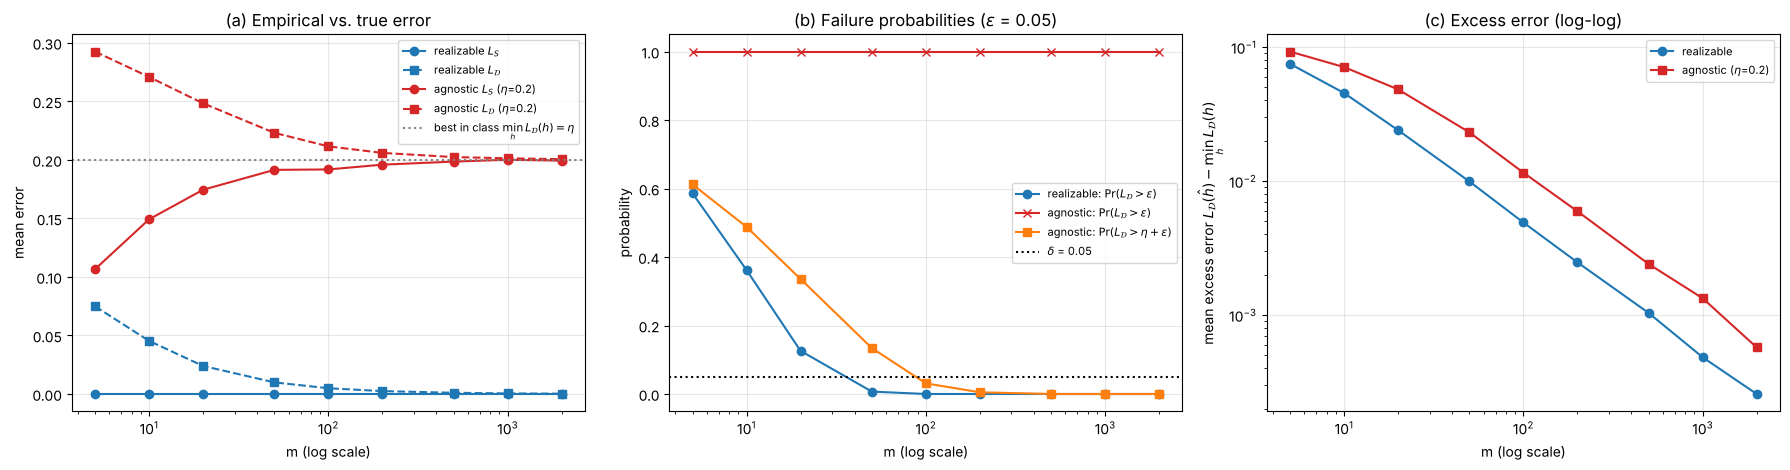

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

ax = axes[0]
ax.plot(M_AGN, emp_R2.mean(1), "o-", color="tab:blue", label=r"realizable $L_S$")
ax.plot(M_AGN, true_R2.mean(1), "s--", color="tab:blue", label=r"realizable $L_\mathcal{D}$")
ax.plot(M_AGN, emp_A.mean(1), "o-", color="tab:red", label=fr"agnostic $L_S$ ($\eta$={ETA})")
ax.plot(M_AGN, true_A.mean(1), "s--", color="tab:red", label=fr"agnostic $L_\mathcal{{D}}$ ($\eta$={ETA})")
ax.axhline(ETA, color="gray", ls=":", label=r"best in class $\min_h L_\mathcal{D}(h)=\eta$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("mean error")
ax.set_title("(a) Empirical vs. true error"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(M_AGN, p_pac_R, "o-", color="tab:blue", label=r"realizable: $\Pr(L_\mathcal{D}>\varepsilon)$")
ax.plot(M_AGN, p_pac_A, "x-", color="tab:red", label=r"agnostic: $\Pr(L_\mathcal{D}>\varepsilon)$")
ax.plot(M_AGN, p_apac_A, "s-", color="tab:orange", label=r"agnostic: $\Pr(L_\mathcal{D}>\eta+\varepsilon)$")
ax.axhline(DELTA, color="k", ls=":", label=fr"$\delta$ = {DELTA}")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("probability")
ax.set_title(fr"(b) Failure probabilities ($\varepsilon$ = {EPS})"); ax.legend(fontsize=8)

ax = axes[2]
ax.plot(M_AGN, true_R2.mean(1), "o-", color="tab:blue", label="realizable")
ax.plot(M_AGN, (true_A - ETA).mean(1), "s-", color="tab:red", label=fr"agnostic ($\eta$={ETA})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("m (log scale)"); ax.set_ylabel(r"mean excess error $L_\mathcal{D}(\hat h)-\min_h L_\mathcal{D}(h)$")
ax.set_title("(c) Excess error (log-log)"); ax.legend(fontsize=8)
plt.tight_layout()

**Interpretation.** (a) Without noise (blue), the empirical error is always 0 and the true error goes to 0. With noise (red), both errors converge to $\eta = 0.2$: the empirical error from below, the true error from above. (b) With noise, $\Pr(L_\mathcal{D}(\hat h) > \varepsilon)$ stays at 1 for every m (red crosses), while the agnostic criterion $\Pr(L_\mathcal{D}(\hat h) > \eta + \varepsilon)$ (orange) goes to 0, but more slowly than in the realizable case (blue). (c) The excess error $L_\mathcal{D}(\hat h) - \min_h L_\mathcal{D}(h)$ goes to 0 in both settings, but for the same m it is about 2 to 3 times larger with noise.

### Effect of the noise level $\eta$

  eta | m=5    | m=10   | m=20   | m=50   | m=100  | m=200  | m=500  | m=1000 | m=2000   <- Pr(L_D > eta + eps)
 0.00 |  0.554 |  0.382 |  0.106 |  0.000 |  0.000 |  0.000 |  0.000 |  0.000 |  0.000
 0.05 |  0.550 |  0.372 |  0.164 |  0.034 |  0.004 |  0.000 |  0.000 |  0.000 |  0.000
 0.10 |  0.612 |  0.446 |  0.220 |  0.062 |  0.012 |  0.000 |  0.000 |  0.000 |  0.000
 0.20 |  0.632 |  0.476 |  0.350 |  0.132 |  0.042 |  0.006 |  0.000 |  0.000 |  0.000
 0.30 |  0.584 |  0.518 |  0.452 |  0.228 |  0.096 |  0.028 |  0.000 |  0.000 |  0.000


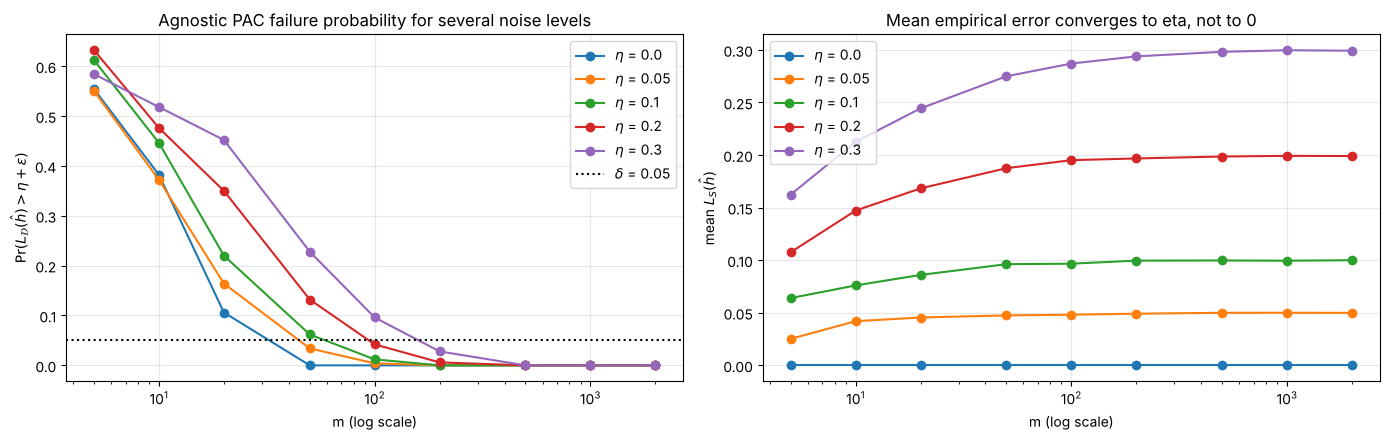

In [14]:
ETAS = [0.0, 0.05, 0.1, 0.2, 0.3]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
print(f"{'eta':>5} | " + " | ".join(f"m={m:<4d}" for m in M_AGN) + "   <- Pr(L_D > eta + eps)")
for eta in ETAS:
    e_emp, e_true = run_experiment(M_AGN, eta=eta, n_rep=500)
    p = np.mean(e_true > eta + EPS, axis=1)
    axes[0].plot(M_AGN, p, "o-", label=fr"$\eta$ = {eta}")
    axes[1].plot(M_AGN, e_emp.mean(1), "o-", label=fr"$\eta$ = {eta}")
    print(f"{eta:5.2f} | " + " | ".join(f"{v:6.3f}" for v in p))
axes[0].axhline(DELTA, color="k", ls=":", label=fr"$\delta$ = {DELTA}")
axes[0].set_xscale("log"); axes[0].set_xlabel("m (log scale)")
axes[0].set_ylabel(r"$\Pr(L_\mathcal{D}(\hat h) > \eta + \varepsilon)$")
axes[0].set_title("Agnostic PAC failure probability for several noise levels"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("m (log scale)"); axes[1].set_ylabel(r"mean $L_S(\hat h)$")
axes[1].set_title("Mean empirical error converges to eta, not to 0"); axes[1].legend()
plt.tight_layout()

### Discussion

**1. Can the empirical error still reach zero?**
No. In the realizable case, $L_S(\hat h) = 0$ in 100% of the runs. With noise, it only happens by chance for very small samples (about 54% of runs for m = 5, 1.4% for m = 20, and never from m = 50), because no single threshold can fit the flipped labels. The mean empirical error tends to η = 0.2. For small m, $L_S$ is even lower than η and lower than the true error: ERM partially fits the noise of the training set, so the training error is too optimistic.

**2. Does increasing the number of training examples still improve generalization?**
Yes, but in a different way. The true error does not go to 0: it goes to η = 0.2, the best error possible in the class (0.292 for m = 5, 0.212 for m = 100, 0.201 for m = 2000). So $\Pr(L_\mathcal{D}(\hat h) > \varepsilon) = 1$ for every m: the PAC criterion can never be satisfied. However, the excess error $L_\mathcal{D}(\hat h) - \eta$ goes to 0, and $\Pr(L_\mathcal{D}(\hat h) > \eta + \varepsilon)$ decreases to 0 (0.61 for m = 5, 0.03 for m = 100, 0 from m = 500). Learning is slower than in the realizable case: we need about m = 100 to go below δ = 0.05 with η = 0.2, instead of m = 50 without noise, and even more when the noise is higher (about m = 200 for η = 0.3).

**3. Link with the PAC and Agnostic PAC frameworks.**
Without noise, the realizability assumption holds (the target $f_\theta$ belongs to $\mathcal{H}$), and we observed the PAC guarantee: $L_\mathcal{D}(\hat h) \le \varepsilon$ with probability at least $1-\delta$ when m is large enough. With noise, realizability fails, so the PAC guarantee is impossible. The right objective is the Agnostic PAC one from the lecture: $L_\mathcal{D}(\hat h) \le \min_{h \in \mathcal{H}} L_\mathcal{D}(h) + \varepsilon$ with probability at least $1-\delta$. Our experiments show that ERM satisfies this when m is large enough, but it needs more data than in the realizable case. Here the best error in the class (η) is also the error of the Bayes optimal predictor, because $P(y=1 \mid x) > 1/2$ exactly when $x > \theta$.

## 6. Conclusion

| | **PAC (realizable, η = 0)** | **Agnostic PAC (noise η = 0.2)** |
|---|---|---|
| Assumption | a perfect threshold exists in $\mathcal{H}$ | no perfect threshold; labels are noisy |
| Empirical error of ERM | always 0 | > 0, tends to η (below η for small m: ERM fits the noise) |
| True error when m grows | goes to 0 | goes to η = 0.2, never below |
| Guarantee observed | $\Pr(L_\mathcal{D}(\hat h) > \varepsilon) \to 0$, below the bound $2(1-\varepsilon)^m$ | $\Pr(L_\mathcal{D}(\hat h) > \varepsilon) = 1$ for all m, but $\Pr(L_\mathcal{D}(\hat h) > \eta + \varepsilon) \to 0$ |
| Reference point | zero error | best error in the class |
| Data needed (ε = δ = 0.05) | about m = 50 | about m = 100 (η = 0.2), about m = 200 (η = 0.3) |

In the realizable setting, ERM over threshold classifiers is PAC: the training error is always zero, and with enough examples the true error is smaller than ε with probability at least 1 − δ. When we add label noise, realizability no longer holds: the training error can no longer reach zero, and the true error can never go below the noise level, so the PAC guarantee is impossible. Learning is still possible in the weaker sense of Agnostic PAC: ERM gets ε-close to the best hypothesis of the class, but it needs more training examples than in the realizable case, and even more when the noise increases.